# NB-P02-01 — Linear Algebra for AI

Companion notebook for [LP02-01](../lessons/LP02-01-scalars-vectors-matrices-and-tensors.md),
[LP02-02](../lessons/LP02-02-matrix-operations-and-multiplication.md) and
[LP02-03](../lessons/LP02-03-transpose-inverse-and-eigenvalues.md).

Every claim in those lessons is checked numerically here. Change a number, rerun, and see which
statements survive.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True, precision=3)
print("NumPy", np.__version__)

NumPy 2.5.3


## 1. Objects and shapes

A scalar is rank 0, a vector rank 1, a matrix rank 2, a tensor rank 3 or more. Rank is the length of the
shape, not the number of elements.

In [2]:
scalar = np.array(3.0)
vector = np.array([3.0, 4.0])
matrix = np.arange(6).reshape(2, 3)
tensor = np.zeros((2, 3, 4))

for name, obj in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("tensor", tensor)]:
    print(f"{name:7s} shape={str(obj.shape):12s} size={obj.size:3d} ndim={obj.ndim}")

scalar  shape=()           size=  1 ndim=0
vector  shape=(2,)         size=  2 ndim=1
matrix  shape=(2, 3)       size=  6 ndim=2
tensor  shape=(2, 3, 4)    size= 24 ndim=3


## 2. Dot products, norms and angles

$\mathbf{a}\cdot\mathbf{b} = \sum_i a_ib_i = \|\mathbf{a}\|\|\mathbf{b}\|\cos\theta$.

In [3]:
a = np.array([1.0, 2.0])
b = np.array([2.0, 1.0])

dot = a @ b
cos = dot / (np.linalg.norm(a) * np.linalg.norm(b))
print("dot      :", dot)
print("|a|, |b| :", round(np.linalg.norm(a), 3), round(np.linalg.norm(b), 3))
print("cos theta:", round(float(cos), 3))
print("theta    :", round(float(np.degrees(np.arccos(cos))), 2), "degrees")

dot      : 4.0
|a|, |b| : 2.236 2.236
cos theta: 0.8
theta    : 36.87 degrees


### Orthogonality, projection, and the law of cosines

In [4]:
u = np.array([1.0, 2.0])
v = np.array([2.0, -1.0])
print("orthogonal dot:", u @ v)

# Projection of a onto b: (a.b / |b|^2) * b
proj = (a @ b) / (b @ b) * b
print("projection of a onto b:", proj)

# |a - b|^2 = |a|^2 + |b|^2 - 2 a.b
lhs = np.linalg.norm(a - b) ** 2
rhs = np.linalg.norm(a) ** 2 + np.linalg.norm(b) ** 2 - 2 * (a @ b)
print("law of cosines holds:", np.isclose(lhs, rhs))

orthogonal dot: 0.0
projection of a onto b: [1.6 0.8]
law of cosines holds: True


## 3. Matrix products

`@` is the matrix product; `*` is elementwise. The inner dimensions must agree:
$(m\times k)(k\times n) = m\times n$.

In [5]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A @ B =\n", A @ B)
print("B @ A =\n", B @ A)
print("A * B (elementwise) =\n", A * B)
print("commutes?", np.array_equal(A @ B, B @ A))

A @ B =
 [[19 22]
 [43 50]]
B @ A =
 [[23 34]
 [31 46]]
A * B (elementwise) =
 [[ 5 12]
 [21 32]]
commutes? False


### A matrix–vector product is a mixture of the columns

$A\mathbf{x} = x_1\mathbf{a}_{:1} + x_2\mathbf{a}_{:2}$.

In [6]:
x = np.array([1, 1])
print("A @ x        :", A @ x)
print("sum of cols  :", A[:, 0] * x[0] + A[:, 1] * x[1])

# By hand, to prove the shape rule is not magic
def matmul(A, B):
    m, k = A.shape
    k2, n = B.shape
    assert k == k2, f"inner shapes differ: {A.shape} @ {B.shape}"
    return np.array([[sum(A[i, p] * B[p, j] for p in range(k)) for j in range(n)] for i in range(m)])


print("hand == NumPy:", np.array_equal(matmul(A, B), A @ B))

A @ x        : [3 7]
sum of cols  : [3 7]
hand == NumPy: True


## 4. Transpose, inverse, determinant

$(AB)^\top = B^\top A^\top$, and $AA^{-1} = I$ only when $\det A \ne 0$.

In [7]:
print("(AB)^T:\n", (A @ B).T)
print("B^T A^T:\n", B.T @ A.T)

C = np.array([[4.0, 7.0], [2.0, 6.0]])
print("det(C):", round(float(np.linalg.det(C)), 6))
print("inv(C):\n", np.linalg.inv(C).round(3))
print("C @ inv(C) is identity:", np.allclose(C @ np.linalg.inv(C), np.eye(2)))

(AB)^T:
 [[19 43]
 [22 50]]
B^T A^T:
 [[19 43]
 [22 50]]
det(C): 10.0
inv(C):
 [[ 0.6 -0.7]
 [-0.2  0.4]]
C @ inv(C) is identity: True


In [8]:
S = np.array([[1.0, 2.0], [2.0, 4.0]])
print("det(S) =", round(float(np.linalg.det(S)), 12))
try:
    np.linalg.inv(S)
except np.linalg.LinAlgError as err:
    print("singular:", err)

det(S) = 0.0
singular: Singular matrix


## 5. Eigenvalues and eigenvectors

$A\mathbf{v} = \lambda\mathbf{v}$. For symmetric matrices use `eigh`: real eigenvalues, sorted,
orthonormal eigenvectors, and two identities to check — trace equals the sum, determinant the product.

In [9]:
M = np.array([[2.0, 1.0], [1.0, 2.0]])
vals, vecs = np.linalg.eigh(M)

print("eigenvalues:", vals)
print("eigenvectors (columns):\n", vecs.round(3))
print("trace check:", round(float(vals.sum()), 6), "==", round(float(np.trace(M)), 6))
print("det check  :", round(float(vals.prod()), 6), "==", round(float(np.linalg.det(M)), 6))

for i in range(2):
    print(f"A v{i+1} =", (M @ vecs[:, i]).round(3), " λ v =", (vals[i] * vecs[:, i]).round(3))

print("eigenvectors orthogonal:", np.isclose(vecs[:, 0] @ vecs[:, 1], 0.0))

eigenvalues: [1. 3.]
eigenvectors (columns):
 [[-0.707  0.707]
 [ 0.707  0.707]]
trace check: 4.0 == 4.0
det check  : 3.0 == 3.0
A v1 = [-0.707  0.707]  λ v = [-0.707  0.707]
A v2 = [2.121 2.121]  λ v = [2.121 2.121]
eigenvectors orthogonal: True


### Eigenvalues as variance directions

Draw a circle, map it through a symmetric matrix, and the result is an ellipse whose axes lie along the
eigenvectors and whose lengths are the eigenvalues.

eigenvalue 1.382 direction [ 0.526 -0.851]
eigenvalue 3.618 direction [-0.851 -0.526]


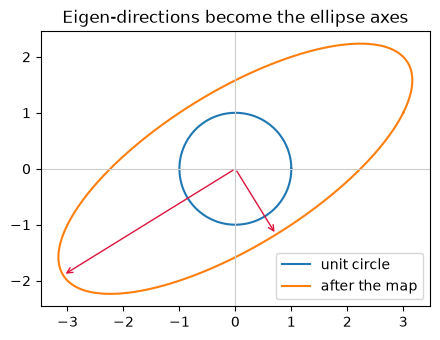

In [10]:
A2 = np.array([[3.0, 1.0], [1.0, 2.0]])
angles = np.linspace(0, 2 * np.pi, 400)
circle = np.stack([np.cos(angles), np.sin(angles)], axis=1)
ellipse = circle @ A2.T
vals2, vecs2 = np.linalg.eigh(A2)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(circle[:, 0], circle[:, 1], label="unit circle")
ax.plot(ellipse[:, 0], ellipse[:, 1], label="after the map")
for value, direction in zip(vals2, vecs2.T):
    ax.annotate("", xy=value * direction, xytext=(0, 0),
                arrowprops={"arrowstyle": "->", "color": "crimson"})
    print("eigenvalue", round(float(value), 3), "direction", direction.round(3))
ax.set_aspect("equal")
ax.axhline(0, color="0.8", linewidth=0.8)
ax.axvline(0, color="0.8", linewidth=0.8)
ax.set_title("Eigen-directions become the ellipse axes")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Least squares without an inverse

Four points, two unknowns: $A$ is not square, so there is no exact solution. The normal equations solve
the closest problem instead.

intercept, slope: [0.15 1.94]
normal equations : [0.15 1.94]
same             : True


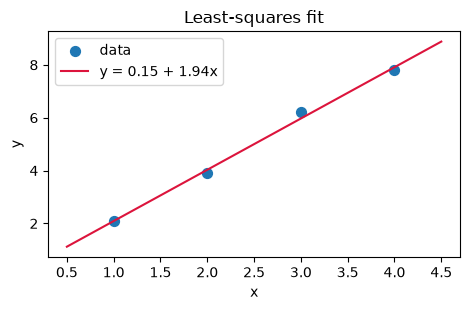

In [11]:
x = np.array([1.0, 2.0, 3.0, 4.0])
y = np.array([2.1, 3.9, 6.2, 7.8])
design = np.column_stack([np.ones_like(x), x])

coef, *_ = np.linalg.lstsq(design, y, rcond=None)
print("intercept, slope:", coef.round(3))

normal = np.linalg.inv(design.T @ design) @ design.T @ y
print("normal equations :", normal.round(3))
print("same             :", np.allclose(coef, normal))

grid = np.linspace(0.5, 4.5, 20)
fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.scatter(x, y, s=50, label="data")
ax.plot(grid, coef[0] + coef[1] * grid, color="crimson", label=f"y = {coef[0]:.2f} + {coef[1]:.2f}x")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Least-squares fit")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Exercises

1. Compute the cosine similarity of `(3, 4)` and `(4, 3)` and of `(3, 4)` and `(-4, 3)`. Explain both.
2. Build a 3×2 matrix and a 2×3 matrix; compute both products and state their shapes.
3. Find the eigenvalues of `[[0, -1], [1, 0]]`. What transformation does this matrix represent, and why
   are the eigenvalues complex?
4. Verify on `A2` that `np.linalg.norm(ellipse, axis=1).max()` equals the largest eigenvalue.

In [12]:
# 1
p, q, r = np.array([3.0, 4.0]), np.array([4.0, 3.0]), np.array([-4.0, 3.0])
cos = lambda u, v: (u @ v) / (np.linalg.norm(u) * np.linalg.norm(v))
print(round(float(cos(p, q)), 3), round(float(cos(p, r)), 3))

0.96 0.0


In [13]:
# 2
P = np.arange(6).reshape(3, 2)
Q = np.arange(6, 12).reshape(2, 3)
print((P @ Q).shape, (Q @ P).shape)

(3, 3) (2, 2)


In [14]:
# 3
R = np.array([[0.0, -1.0], [1.0, 0.0]])
print(np.linalg.eigvals(R))

[0.+1.j 0.-1.j]


In [15]:
# 4
print(round(float(np.linalg.norm(ellipse, axis=1).max()), 3), round(float(vals2.max()), 3))

3.618 3.618


## 8. Check yourself

1. Why is `A @ B` not equal to `B @ A` in general, and when *is* it equal?
2. What does `det A = 0` imply about the eigenvalues and about solving $A\mathbf{x} = \mathbf{b}$?
3. Why does `lstsq` give a unique answer even though $A$ has no inverse?

Next: [NB-P02-02](nb-p02-02-calculus-and-optimization.ipynb).